# TP 2: Simple neural networks

## Part 1: Implement a multilayer perceptron (MLP) and a convolutional neural network (CNN) for Fashion-MNIST

Official PyTorch tutorials: [Learn the Basics](https://pytorch.org/tutorials/beginner/basics/intro.html) · [Deep Learning with PyTorch: A 60 Minute Blitz](https://pytorch.org/tutorials/beginner/deep_learning_60min_blitz.html)

### 1. Import the required packages

Some modules are imported when they are first used in this notebook. In a Python script, imports are usually grouped at the beginning.

**Reproducibility:** use `SEED = 42` for the data split, model initialization, and shuffled training batches. Before repeating an experiment, rerun the model/optimizer initialization cell and then the training loop; these initialization cells also reset the training data generator. Restart the kernel and run all cells for a complete repeat. Results can still differ across devices or PyTorch versions, and a seed alone does not guarantee deterministic GPU operations. See [PyTorch reproducibility](https://docs.pytorch.org/docs/stable/notes/randomness.html).


In [1]:
import scipy
import numpy as np  # N-dimensional arrays
import pandas as pd  # Data frames
import matplotlib.pyplot as plt  # Plotting
import seaborn  # Statistical visualizations
from sklearn import preprocessing  # Data preprocessing
# SciPy provides scientific computing routines.

import os

import torch
import random

SEED = 42 # Fix a random seed for reproducibility


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


set_seed()


Check the PyTorch version.

In [2]:
torch.__version__

'2.14.0'

Check GPU availability: CUDA for NVIDIA GPUs, or MPS (Metal Performance Shaders) for Apple GPUs.

In [3]:
print("CUDA available:", torch.cuda.is_available())
print("MPS available:", torch.backends.mps.is_available())

CUDA available: False
MPS available: True


In [4]:
if torch.cuda.is_available():
    print("CUDA GPU count:", torch.cuda.device_count())
elif torch.backends.mps.is_available():
    print("Apple GPU available through MPS")
else:
    print("No supported GPU detected; using the CPU")

Apple GPU available through MPS


Select the device automatically. Models and input tensors must be moved to the same device using `.to(device)`.

See [PyTorch GPU acceleration on Mac](https://developer.apple.com/metal/pytorch/) for details.

In [5]:
if torch.cuda.is_available():
    device = torch.device("cuda:0")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

print(f"Using {device} device")

Using mps device


### 2. Load and preprocess the data

Download Fashion-MNIST using `torchvision.datasets`. See the [torchvision datasets documentation](https://pytorch.org/vision/stable/datasets.html).

In [6]:
import torchvision
import torchvision.transforms as transforms

In [7]:
transform = transforms.Compose([transforms.ToTensor(),transforms.Normalize((0.5, ), (0.5, ))]) 

dataset = torchvision.datasets.FashionMNIST(root='./data', train=True,
                                        download=True, transform=transform)

testset = torchvision.datasets.FashionMNIST(root='./data', train=False,
                                       download=True, transform=transform)

> Define the preprocessing pipeline before creating the dataset, then pass it through the dataset's `transform` argument, as in `transform=transform` above.
>
> For the 8-bit Fashion-MNIST images used here, `ToTensor()` converts pixel values from integers in $[0,255]$ to floating-point values in $[0,1]$ and returns a tensor with shape `(channels, height, width)`. This scaling alone can be a reasonable baseline; whether additional normalization helps should be assessed on the validation set.
>
> `Normalize((mean,), (std,))` applies the following transformation to each channel:
>
> $$
> x_{\mathrm{norm}}=\frac{x-\mathrm{mean}}{\mathrm{std}}.
> $$
>
> The one-element tuples specify one mean and one standard deviation because Fashion-MNIST images have a single grayscale channel.
>
> In the code above, `mean=0.5` and `std=0.5` rescale pixel values from $[0,1]$ to $[-1,1]$. These constants do not represent the dataset's mean and standard deviation, so this does not produce zero-mean, unit-variance data.
>
> To standardize using dataset statistics, first estimate the mean and standard deviation across all training pixels after scaling to $[0,1]$, but before applying `Normalize`. If a validation set is held out, exclude it from this calculation. Use the same training-set statistics for the training, validation, and test sets to avoid data leakage.
>
> For the full Fashion-MNIST training set, the approximate values are `mean = 0.2860` and `std = 0.3530`; estimates may differ slightly when using a training subset.
>
> The dataset applies its `transform` pipeline whenever an image is retrieved, either directly (for example, `dataset[i]`) or through a `DataLoader`.
>
> Use `transforms.Compose([...])` to apply several preprocessing steps in sequence. Here, `ToTensor()` must precede `Normalize`, which operates on tensors.
>
> To map values from $[0,1]$ to another interval $[a,b]$, a custom transform can apply $x \mapsto a + (b-a)x$ after `ToTensor()`.

Official documentation: [ToTensor](https://docs.pytorch.org/vision/main/generated/torchvision.transforms.ToTensor.html) · [Normalize](https://docs.pytorch.org/vision/main/generated/torchvision.transforms.Normalize.html) · [Compose](https://docs.pytorch.org/vision/main/generated/torchvision.transforms.Compose.html)

Further reading: [Transforms tutorial](https://docs.pytorch.org/tutorials/beginner/basics/transforms_tutorial.html) · [Datasets and DataLoaders tutorial](https://docs.pytorch.org/tutorials/beginner/basics/data_tutorial.html)


Inspect `dataset`.

In [8]:
dataset

Dataset FashionMNIST
    Number of datapoints: 60000
    Root location: ./data
    Split: Train
    StandardTransform
Transform: Compose(
               ToTensor()
               Normalize(mean=(0.5,), std=(0.5,))
           )

Store the number of classes for use when defining the model architecture.

In [9]:
classes = dataset.classes
classes

['T-shirt/top',
 'Trouser',
 'Pullover',
 'Dress',
 'Coat',
 'Sandal',
 'Shirt',
 'Sneaker',
 'Bag',
 'Ankle boot']

In [10]:
n_classes = len(classes)
n_classes

10

In [11]:
dataset.class_to_idx

{'T-shirt/top': 0,
 'Trouser': 1,
 'Pullover': 2,
 'Dress': 3,
 'Coat': 4,
 'Sandal': 5,
 'Shirt': 6,
 'Sneaker': 7,
 'Bag': 8,
 'Ankle boot': 9}

Check whether the classes are balanced.

In [12]:
class_count = {}
for _, index in dataset:
    label = classes[index]
    if label not in class_count:
        class_count[label] = 0
    class_count[label] += 1
class_count

{'Ankle boot': 6000,
 'T-shirt/top': 6000,
 'Dress': 6000,
 'Pullover': 6000,
 'Sneaker': 6000,
 'Sandal': 6000,
 'Trouser': 6000,
 'Shirt': 6000,
 'Coat': 6000,
 'Bag': 6000}

In [13]:
dataset.data.shape

torch.Size([60000, 28, 28])

In [14]:
dataset.data.dtype

torch.uint8

Split the training data into training and validation subsets. Use stratification to preserve the class proportions.

See the [PyTorch data-loading documentation](https://pytorch.org/docs/stable/data.html) for details on datasets, subsets, and data loaders.

In [15]:
from sklearn.model_selection import train_test_split
random_state = SEED  # Reproducible train/validation split
train_indices, val_indices = train_test_split(list(range(len(dataset.targets))), test_size=10000, stratify=dataset.targets,random_state=random_state)

Alternatively, use `torch.utils.data.random_split`. This method does not stratify by class, so it does not guarantee that class proportions are preserved.

In [16]:
# trainset,valset = torch.utils.data.random_split(trainset, [40000,10000],generator=torch.Generator().manual_seed(random_state))

In [17]:
trainset = torch.utils.data.Subset(dataset, train_indices)
valset = torch.utils.data.Subset(dataset, val_indices)

After creating the training and validation subsets, use a `DataLoader` to iterate over each dataset in batches.

In [18]:
batch_size = 64

# Separate generators keep data loading independent of model initialization.
train_generator = torch.Generator().manual_seed(SEED)
trainloader = torch.utils.data.DataLoader(
    trainset, batch_size=batch_size, shuffle=True, num_workers=2,
    generator=train_generator,
)
valloader = torch.utils.data.DataLoader(
    valset, batch_size=batch_size, shuffle=False, num_workers=2,
    generator=torch.Generator().manual_seed(SEED),
)
testloader = torch.utils.data.DataLoader(
    testset, batch_size=batch_size, shuffle=False, num_workers=2,
    generator=torch.Generator().manual_seed(SEED),
)


Official documentation: [DataLoader](https://docs.pytorch.org/docs/2.14/data.html#torch.utils.data.DataLoader)

Visualize a grid of images.

See [Visualizing a grid of images](https://pytorch.org/vision/stable/auto_examples/plot_visualization_utils.html#visualizing-a-grid-of-images).

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..1.0].


images.shape: torch.Size([64, 1, 28, 28])


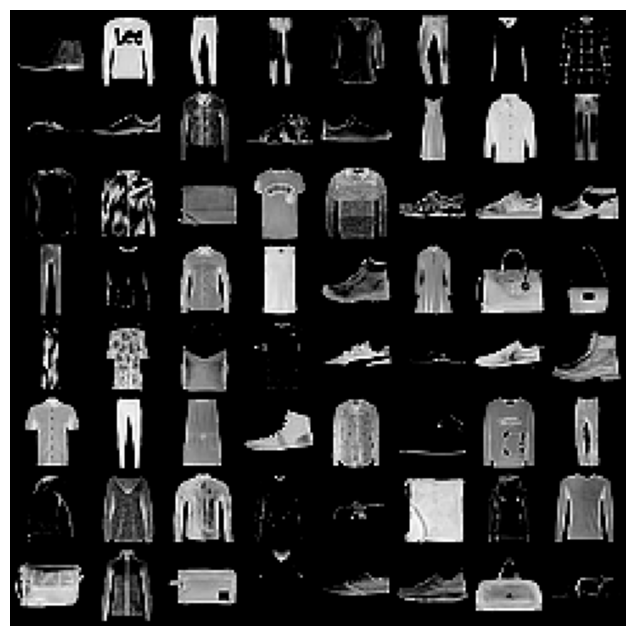

In [19]:
from torchvision.utils import make_grid
for images, _ in testloader:
    print('images.shape:', images.shape)
    plt.figure(figsize=(8,8))
    plt.axis('off')
    plt.imshow(make_grid(images, nrow=8).permute((1, 2, 0)))
    break

### 3. Implement and train an MLP with two hidden layers

Useful documentation: [Functional API](https://pytorch.org/docs/stable/nn.functional.html) · [Linear](https://pytorch.org/docs/stable/generated/torch.nn.Linear.html) · [Flatten](https://docs.pytorch.org/docs/2.14/generated/torch.nn.modules.flatten.Flatten.html) · [ReLU](https://docs.pytorch.org/docs/2.14/generated/torch.nn.ReLU.html) · [nn](https://docs.pytorch.org/docs/main/nn.html) 

In [20]:
import torch.nn as nn

class FullyConnected(nn.Module):
    def __init__(self,n_classes):
        super(FullyConnected, self).__init__()
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(28*28, 256)
        self.fc2 = nn.Linear(256, 128)
        self.fc3 = nn.Linear(128, n_classes)
        self.relu = nn.ReLU()


    def forward(self, x):
        x = self.flatten(x)
        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))
        x = self.fc3(x)
        return x

Initialize the model.

In [21]:
set_seed()
train_generator.manual_seed(SEED)
net = FullyConnected(n_classes = n_classes)

In [22]:
net.to(device)  # Move the model to the selected device

FullyConnected(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc1): Linear(in_features=784, out_features=256, bias=True)
  (fc2): Linear(in_features=256, out_features=128, bias=True)
  (fc3): Linear(in_features=128, out_features=10, bias=True)
  (relu): ReLU()
)

Define the loss function and optimizer.

In [23]:
import torch.optim as optim

criterion = nn.CrossEntropyLoss()
output_fn = nn.Softmax(dim=1)
optimizer = optim.Adam(net.parameters(), lr=0.001)

Define a simple training loop and train the model.

In [24]:
def train(model, device, train_loader, optimizer, criterion):
    model.train()
    for epoch in range(5):
        for batch_idx, (data, target) in enumerate(train_loader):
            data, target = data.to(device), target.to(device)
            optimizer.zero_grad()
            output = model(data)
            loss = criterion(output, target)
            loss.backward()
            optimizer.step()
        print(f"Epoch {epoch + 1}: Loss = {loss.item():.4f}")

In [25]:
train(net, device, trainloader, optimizer, criterion)

Epoch 1: Loss = 0.4566
Epoch 2: Loss = 0.3930
Epoch 3: Loss = 0.2345
Epoch 4: Loss = 0.4489
Epoch 5: Loss = 0.3923


Evaluate the model on the test set (simple version).

In [26]:
def test(model, device, test_loader):
    model.eval()
    correct = 0
    with torch.no_grad():
        for data, target in test_loader:
            data, target = data.to(device), target.to(device)
            output = model(data)
            pred = output_fn(output).argmax(dim=1, keepdim=True)  # Equivalently: output.argmax(dim=1, keepdim=True) 
            correct += pred.eq(target.view_as(pred)).sum().item()
    accuracy = correct / len(test_loader.dataset)
    print(f"PyTorch Model Accuracy: {accuracy:.4f}")


In [27]:
test(net, device, testloader)

PyTorch Model Accuracy: 0.8789


#### Further exercises

1. Monitor training with a validation set: create a validation subset, evaluate the model after each epoch, and reserve the test set for the final evaluation.
2. Add early stopping
3. Compare different optimizers.

Answers:

For (1-2), part of the solution is provided below: the training loop uses a validation set and includes early stopping.

(3) To try another optimizer, replace `optim.Adam(...)` with another type, such as `optim.SGD(...)`. To change the learning rate, modify the `lr` argument. Then reinitialize the model, create the optimizer with the new settings, and rerun the training loop.

> Can you conclude that one optimizer is better by testing only one learning rate for each?

No. A suitable learning rate depends on the optimizer. Try several learning rates for each optimizer and compare validation performance and convergence speed.


##### Training with TorchMetrics and early stopping

Each epoch reports sample-level accuracy using [TorchMetrics](https://lightning.ai/docs/torchmetrics/stable/classification/accuracy.html). Accuracy accumulates across all batches and is computed once per epoch; separate training, validation, and test metrics are reset at the start of each function call to prevent state from leaking between epochs or datasets. Raw logits can be passed directly to the metric.

In [28]:
from torchmetrics.classification import MulticlassAccuracy


def train_one_epoch(model, dataloader, criterion, optimizer, device, accuracy_metric):
    model.train()
    accuracy_metric.reset()
    total_loss = 0.0
    total_samples = 0

    for inputs, labels in dataloader:
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer.zero_grad(set_to_none=True)
        logits = model(inputs)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()

        batch_size = labels.size(0)
        total_loss += loss.item() * batch_size
        total_samples += batch_size
        accuracy_metric.update(logits.detach(), labels)

    if total_samples == 0:
        raise ValueError("The training dataloader is empty.")

    return {"loss": total_loss / total_samples, "accuracy": accuracy_metric.compute().item()}


In [29]:
def evaluate(model, dataloader, criterion, device, accuracy_metric):
    model.eval()
    accuracy_metric.reset()
    total_loss = 0.0
    total_samples = 0

    with torch.inference_mode():
        for inputs, labels in dataloader:
            inputs, labels = inputs.to(device), labels.to(device)
            logits = model(inputs)
            loss = criterion(logits, labels)

            batch_size = labels.size(0)
            total_loss += loss.item() * batch_size
            total_samples += batch_size
            accuracy_metric.update(logits, labels)

        if total_samples == 0:
            raise ValueError("The evaluation dataloader is empty.")

        epoch_accuracy = accuracy_metric.compute().item()
    return {"loss": total_loss / total_samples, "accuracy": epoch_accuracy}


Note that `model.eval()` prepares the model for evaluation: it disables `Dropout` and makes `BatchNorm` use the statistics learned during training. It does not disable gradient tracking.
`torch.inference_mode()` disables gradient tracking and reduces computation overhead. For validation and testing, it can replace `torch.no_grad()`. Keep `no_grad()` when outputs must subsequently participate in such computations—for example, extracting frozen features to train another network.

Before training again, call `model.train()`.

In [38]:
# Start independently of the earlier simple training example.
set_seed()
train_generator.manual_seed(SEED)
net = FullyConnected(n_classes=n_classes).to(device)
optimizer = optim.Adam(net.parameters(), lr=0.001)
criterion = nn.CrossEntropyLoss()

train_accuracy_metric = MulticlassAccuracy(num_classes=n_classes, average="micro").to(device)
val_accuracy_metric = MulticlassAccuracy(num_classes=n_classes, average="micro").to(device)
test_accuracy_metric = MulticlassAccuracy(num_classes=n_classes, average="micro").to(device)

epochs = 25

Train with a direct epoch loop. `patience=5` stops training after five consecutive epochs without a validation-loss improvement greater than `min_delta=1e-4`. Save a checkpoint whenever this threshold is met, then restore the last saved checkpoint before testing, even if training reaches the maximum number of epochs.

Training and validation loss and accuracy are stored in `history`. The checkpoint contains model weights for evaluation; it does not include optimizer state for resuming training.


In [39]:
from tqdm import tqdm
history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": [],
}

best_val_loss = float("inf")
epochs_without_improvement = 0
patience = 5
min_delta = 1e-4

for epoch in tqdm(range(epochs)):
    train_metrics = train_one_epoch(
        net, trainloader, criterion, optimizer, device, train_accuracy_metric
    )
    val_metrics = evaluate(
        net, valloader, criterion, device, val_accuracy_metric
    )

    history["train_loss"].append(train_metrics["loss"])
    history["train_accuracy"].append(train_metrics["accuracy"])
    history["val_loss"].append(val_metrics["loss"])
    history["val_accuracy"].append(val_metrics["accuracy"])

    print(
        f"Epoch {epoch + 1:02d}/{epochs} | "
        f"train loss: {train_metrics['loss']:.4f} | "
        f"train accuracy: {train_metrics['accuracy']:.4f} | "
        f"val loss: {val_metrics['loss']:.4f} | "
        f"val accuracy: {val_metrics['accuracy']:.4f}"
    )

    if val_metrics["loss"] < best_val_loss - min_delta:
        best_val_loss = val_metrics["loss"]
        epochs_without_improvement = 0
        print(f"Saving best model at epoch {epoch + 1} with val loss {best_val_loss:.4f}.")
        torch.save(net.state_dict(), "best_model_mlp.pth")
    else:
        epochs_without_improvement += 1
        if epochs_without_improvement >= patience:
            print(f"Early stopping at epoch {epoch + 1}.")
            break

# Restore the checkpoint selected by validation loss before testing.
net.load_state_dict(
    torch.load("best_model_mlp.pth", map_location=device, weights_only=True)
)
net.eval()

  4%|▍         | 1/25 [00:06<02:39,  6.65s/it]

Epoch 01/25 | train loss: 0.5184 | train accuracy: 0.8111 | val loss: 0.3907 | val accuracy: 0.8606
Saving best model at epoch 1 with val loss 0.3907.


  8%|▊         | 2/25 [00:12<02:22,  6.20s/it]

Epoch 02/25 | train loss: 0.3770 | train accuracy: 0.8619 | val loss: 0.3377 | val accuracy: 0.8791
Saving best model at epoch 2 with val loss 0.3377.


 12%|█▏        | 3/25 [00:17<02:05,  5.69s/it]

...

 44%|████▍     | 11/25 [01:02<01:18,  5.59s/it]

Epoch 11/25 | train loss: 0.2163 | train accuracy: 0.9176 | val loss: 0.3175 | val accuracy: 0.8882


 44%|████▍     | 11/25 [01:08<01:27,  6.23s/it]

Epoch 12/25 | train loss: 0.2040 | train accuracy: 0.9214 | val loss: 0.3133 | val accuracy: 0.8946
Early stopping at epoch 12.


FullyConnected(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc1): Linear(in_features=784, out_features=256, bias=True)
  (fc2): Linear(in_features=256, out_features=128, bias=True)
  (fc3): Linear(in_features=128, out_features=10, bias=True)
  (relu): ReLU()
)

##### Final test evaluation

Once training and model selection are complete, evaluate the restored best model on the test set. The test set is never used for early stopping.

In [41]:
test_metrics = evaluate(net, testloader, criterion, device, test_accuracy_metric)
print("Test: " + " | ".join(f"{name}: {value:.4f}" for name, value in test_metrics.items()))


Test: loss: 0.3312 | accuracy: 0.8832


### 4. Implement and train a LeNet model

Useful documentation: [Conv2d](https://pytorch.org/docs/stable/generated/torch.nn.Conv2d.html) · [MaxPool2d](https://pytorch.org/docs/stable/generated/torch.nn.MaxPool2d.html) 


In [33]:
import torch.nn as nn

class LeNet(nn.Module):
    def __init__(self,n_classes=10):
      # Define the convolutional and fully connected layers
      super().__init__()
      self.conv1 = nn.Conv2d(in_channels=1, out_channels=6, kernel_size=5,stride=1,padding=2)
      self.conv2 = nn.Conv2d(in_channels=6, out_channels=16, kernel_size=5)
      self.pool1 = nn.AvgPool2d(kernel_size=2,stride=2)
      self.pool2 = nn.AvgPool2d(kernel_size=2,stride=2)
      self.fc1 = nn.Linear(in_features=400, out_features=120)
      self.fc2 = nn.Linear(in_features=120, out_features=84)
      self.fc3 = nn.Linear(in_features=84, out_features=n_classes)
      self.flatten = nn.Flatten()
      self.tanh = nn.Tanh()

    def forward(self, x):
      x = self.tanh(self.conv1(x))
      x = self.pool1(x)
      x = self.tanh(self.conv2(x))
      x = self.pool2(x)
      x = self.flatten(x)
      x = self.tanh(self.fc1(x))
      x = self.tanh(self.fc2(x))
      x = self.fc3(x)
      return x


#### A variant using `nn.Sequential`

In [ ]:
class Net(nn.Module):

    def __init__(self, n_classes=10):
        super().__init__()

        self.features = nn.Sequential(
            # Shapes are (channels, height, width), assuming 28 × 28 inputs.
            nn.Conv2d(1, 6, kernel_size=5,padding = 2, stride = 1),
            nn.Tanh(),
            nn.AvgPool2d(kernel_size=2, stride=2),
            nn.Conv2d(6, 16, kernel_size=5,stride = 1),
            nn.Tanh(),
            nn.AvgPool2d(kernel_size=2, stride=2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(16 * 5 * 5, 120),
            nn.Tanh(),
            nn.Linear(120, 84),
            nn.Tanh(),
            nn.Linear(84, n_classes)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)

Define the loss function and optimizer.

In [44]:
import torch.optim as optim
# Start independently of the earlier simple training example.
set_seed()
train_generator.manual_seed(SEED)
net = LeNet(n_classes=n_classes).to(device)
optimizer = optim.Adam(net.parameters(), lr=0.001)
criterion = nn.CrossEntropyLoss()

train_accuracy_metric = MulticlassAccuracy(num_classes=n_classes, average="micro").to(device)
val_accuracy_metric = MulticlassAccuracy(num_classes=n_classes, average="micro").to(device)
test_accuracy_metric = MulticlassAccuracy(num_classes=n_classes, average="micro").to(device)

epochs = 25

Train the model using previous training loop

In [45]:
from tqdm import tqdm
history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": [],
}

best_val_loss = float("inf")
epochs_without_improvement = 0
patience = 5
min_delta = 1e-4

for epoch in tqdm(range(epochs)):
    train_metrics = train_one_epoch(
        net, trainloader, criterion, optimizer, device, train_accuracy_metric
    )
    val_metrics = evaluate(
        net, valloader, criterion, device, val_accuracy_metric
    )

    history["train_loss"].append(train_metrics["loss"])
    history["train_accuracy"].append(train_metrics["accuracy"])
    history["val_loss"].append(val_metrics["loss"])
    history["val_accuracy"].append(val_metrics["accuracy"])

    print(
        f"Epoch {epoch + 1:02d}/{epochs} | "
        f"train loss: {train_metrics['loss']:.4f} | "
        f"train accuracy: {train_metrics['accuracy']:.4f} | "
        f"val loss: {val_metrics['loss']:.4f} | "
        f"val accuracy: {val_metrics['accuracy']:.4f}"
    )

    if val_metrics["loss"] < best_val_loss - min_delta:
        best_val_loss = val_metrics["loss"]
        epochs_without_improvement = 0
        print(f"Saving best model at epoch {epoch + 1} with val loss {best_val_loss:.4f}.")
        torch.save(net.state_dict(), "best_model_cnn.pth")
    else:
        epochs_without_improvement += 1
        if epochs_without_improvement >= patience:
            print(f"Early stopping at epoch {epoch + 1}.")
            break

# Restore the checkpoint selected by validation loss before testing.
net.load_state_dict(
    torch.load("best_model_cnn.pth", map_location=device, weights_only=True)
)
net.eval()


  4%|▍         | 1/25 [00:07<03:04,  7.67s/it]

Epoch 01/25 | train loss: 0.6108 | train accuracy: 0.7804 | val loss: 0.4158 | val accuracy: 0.8510
Saving best model at epoch 1 with val loss 0.4158.


  8%|▊         | 2/25 [00:14<02:51,  7.45s/it]

Epoch 02/25 | train loss: 0.3941 | train accuracy: 0.8559 | val loss: 0.3643 | val accuracy: 0.8687
Saving best model at epoch 2 with val loss 0.3643.


 12%|█▏        | 3/25 [00:22<02:42,  7.41s/it]

...

 60%|██████    | 15/25 [01:44<01:08,  6.85s/it]

Epoch 15/25 | train loss: 0.1799 | train accuracy: 0.9328 | val loss: 0.2826 | val accuracy: 0.9024


 60%|██████    | 15/25 [01:51<01:14,  7.40s/it]

Epoch 16/25 | train loss: 0.1703 | train accuracy: 0.9364 | val loss: 0.2942 | val accuracy: 0.8972
Early stopping at epoch 16.


LeNet(
  (conv1): Conv2d(1, 6, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
  (conv2): Conv2d(6, 16, kernel_size=(5, 5), stride=(1, 1))
  (pool1): AvgPool2d(kernel_size=2, stride=2, padding=0)
  (pool2): AvgPool2d(kernel_size=2, stride=2, padding=0)
  (fc1): Linear(in_features=400, out_features=120, bias=True)
  (fc2): Linear(in_features=120, out_features=84, bias=True)
  (fc3): Linear(in_features=84, out_features=10, bias=True)
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (tanh): Tanh()
)

#### Evaluate the network on the test set

In [46]:
test_metrics = evaluate(net, testloader, criterion, device, test_accuracy_metric)
print("Test: " + " | ".join(f"{name}: {value:.4f}" for name, value in test_metrics.items()))

Test: loss: 0.3116 | accuracy: 0.8858


#### Further exercises

1. **Compare the CNN and MLP.** Record the following metrics:

| Model | Parameters | Validation accuracy | Test accuracy | Training time |
| ----- | ---------: | ------------------: | ------------: | ------------: |
| MLP   |     |             |        |   |
| CNN (LeNet) |  |             |        |   |

Here the code to count the trainable parameters in the current model.
```python
number_of_parameters = sum(
    parameter.numel()
    for parameter in net.parameters()
    if parameter.requires_grad
)
```

Possible solution:
| Model | Parameters | Validation accuracy | Test accuracy | Training time |
| ----- | ---------: | ------------------: | ------------: | ------------: |
| MLP   | 235,146    | 89.46%              | 88.32%        | ≈ 1 min 09 s  |
| CNN (LeNet) | 61,706 | 89.97%             | 88.58%        | ≈ 1 min 55 s  |

Validation accuracy corresponds to the checkpoint selected by validation loss: epoch 7 for the MLP and epoch 11 for LeNet. Early stopping occurred at epochs 12 and 16, respectively. Times are approximate elapsed times from the progress bars and include validation. Here, we can see a small gain on test accuracy with LeNet architecture. In terms of training time, LeNet require more epochs to be trained but the model has fewer parameters.

2. **Modernize LeNet.** Replace `average pooling` with `max pooling` and the hidden-layer `Tanh` activations with `ReLU`.

3. **Explore other architecture and training choices.** In addition to max pooling and ReLU, vary the convolutional kernel sizes, channel counts, numbers of convolutional and fully connected layers, learning rate, initialization, and number of training epochs. Use the validation set to guide these choices.

A more modern CNN can include:

- More convolutional filters.
- `BatchNorm2d` layers.
- Multiple convolutions per block.
- `AdaptiveAvgPool2d` to produce a fixed spatial output size.
- `Dropout`.
- A smaller classification head.

Adapted from [Dive into Deep Learning: LeNet](http://d2l.ai/chapter_convolutional-neural-networks/lenet.html).

For the evaluation, you can check if some classes are hardest to distinguish. In this case, you can use confusion matrices. You can have a look on the types of errors made by the different models trained and check whether your proposal architectures improve performance equally across classes.
A confusion matrix is available on TorchMetrics: [link](https://lightning.ai/docs/torchmetrics/stable/classification/confusion_matrix).